In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Display all rows
pd.set_option('display.max_rows', None)

# Display all columns
pd.set_option('display.max_columns', None)

# Display full column width (prclickstream truncation of long strings/text)
pd.set_option('display.max_colwidth', None)

# Ensure the output width accommodates all columns in a console
pd.set_option('display.width', None)

In [2]:
data_path = Path("../data/raw")

In [3]:
products = pd.read_csv(data_path/'product.csv', on_bad_lines='skip')

# Focus on product

In [4]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44424 entries, 0 to 44423
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  44424 non-null  int64  
 1   gender              44424 non-null  object 
 2   masterCategory      44424 non-null  object 
 3   subCategory         44424 non-null  object 
 4   articleType         44424 non-null  object 
 5   baseColour          44409 non-null  object 
 6   season              44403 non-null  object 
 7   year                44423 non-null  float64
 8   usage               44107 non-null  object 
 9   productDisplayName  44417 non-null  object 
dtypes: float64(1), int64(1), object(8)
memory usage: 3.4+ MB


In [5]:
cat_cols = ['gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'usage']
for col in cat_cols:
    products[col] = products[col].astype('category')

products['year'] = products['year'].astype('Int64')

In [6]:
products.isna().sum()

id                      0
gender                  0
masterCategory          0
subCategory             0
articleType             0
baseColour             15
season                 21
year                    1
usage                 317
productDisplayName      7
dtype: int64

I can replate missing values but i will add a flag column to see if customers interest change if their informations arent complete.

In [7]:
products['metadata_status'] = 'Complete'
products.loc[products.isnull().any(axis=1), 'metadata_status'] = 'Incomplete'
products['metadata_status'] = products['metadata_status'].astype('category')

### year

In [8]:
products[products['year'].isna()]

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,metadata_status
21272,53781,Men,Apparel,Topwear,Tshirts,Blue,NaN,<NA>,Sports,Puma Men Blue Sless Round Neck T-shirt,Incomplete


In [9]:
products['season'] = products['season'].cat.add_categories(['Unspecified'])
products.loc[products['year'].isna(), 'season'] = 'Unspecified'


Im afraid that replacing a year will bias the data

In [10]:
products.loc[products['year'].isna(), 'year'] = -1

### baseColour

In [11]:
products[(products['baseColour'].isna())]

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,metadata_status
6206,11293,Men,Apparel,Bottomwear,Jeans,NaN,Fall,2016,Casual,Wrangler Men Blue Texas Jeans,Incomplete
9516,41347,Men,Apparel,Bottomwear,Jeans,NaN,Fall,2016,Casual,Wrangler Men Black Texas Jeans,Incomplete
12763,11288,Men,Apparel,Bottomwear,Jeans,NaN,Fall,2016,Casual,Wrangler Men Blue Texas Jeans,Incomplete
14291,30991,Women,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN,Incomplete
15526,57698,Women,Personal Care,Skin,Face Moisturisers,NaN,Spring,2017,Casual,Lotus Herbals Quincenourish Quince Seed Nourishment Massage Cream,Incomplete
15708,41355,Men,Apparel,Bottomwear,Jeans,NaN,Fall,2016,Casual,Wrangler Men Blue Millard Jeans,Incomplete
17268,43122,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,GUESS Man Eau De Toilette 75 ml,Incomplete
17639,45687,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN,Incomplete
20209,11309,Men,Apparel,Bottomwear,Jeans,NaN,Fall,2016,Casual,Wrangler Men Blue Floyd Jeans,Incomplete
23484,45698,Women,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN,Incomplete


In [12]:
# 1. List of colors we expect to find in your product names
colors_to_find = ['Blue', 'Black', 'Red', 'White', 'Grey', 'Green']

# 2. Loop through the colors and fill only the NaNs
for color in colors_to_find:
    # Condition: color is missing AND the display name contains the color string
    mask = (products['baseColour'].isna()) & \
           (products['productDisplayName'].str.contains(color, case=False, na=False))
    
    products.loc[mask, 'baseColour'] = color

In [13]:
products.isnull().sum()

id                      0
gender                  0
masterCategory          0
subCategory             0
articleType             0
baseColour              9
season                 20
year                    0
usage                 317
productDisplayName      7
metadata_status         0
dtype: int64

In [14]:
products[products['baseColour'].isna()]

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,metadata_status
14291,30991,Women,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN,Incomplete
15526,57698,Women,Personal Care,Skin,Face Moisturisers,NaN,Spring,2017,Casual,Lotus Herbals Quincenourish Quince Seed Nourishment Massage Cream,Incomplete
17268,43122,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,GUESS Man Eau De Toilette 75 ml,Incomplete
17639,45687,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN,Incomplete
23484,45698,Women,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN,Incomplete
37531,30992,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN,Incomplete
40675,43119,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,NaN,Incomplete
43260,43116,Women,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,GUESS Seductive Women EDT Spray,Incomplete
44224,43120,Men,Personal Care,Fragrance,Perfume and Body Mist,NaN,Spring,2017,NaN,GUESS by Marciano Men Eau De Toilette 50 ml,Incomplete


master category, usage

In [15]:
# Clean strings before categorizing to prevent duplicate groups
for col in ['masterCategory', 'subCategory', 'articleType']:
    products[col] = products[col].astype(str).str.strip().str.title().astype('category')

In [16]:
# Create a mask for Personal Care
pc_mask = products['masterCategory'] == 'Personal Care'

# If 'usage' is missing in Personal Care, it's safe to say 'Casual'
products.loc[pc_mask & products['usage'].isna(), 'usage'] = 'Casual'

# If 'baseColour' is missing in Personal Care, 'Not Specified' is the most honest label
if 'Not Specified' not in products['baseColour'].dtype.categories:
    products['baseColour'] = products['baseColour'].cat.add_categories(['Unspecified'])

products.loc[pc_mask & products['baseColour'].isna(), 'baseColour'] = 'Unspecified'

In [17]:
products[products['season'].isna()]

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,metadata_status
282,5402,Women,Footwear,Shoes,Sports Shoes,Purple,NaN,2011,Sports,Kalenji Ekiden 200 Wn Purple 2011,Incomplete
5997,5389,Unisex,Footwear,Shoes,Sports Shoes,Yellow,NaN,2011,Sports,Kalenji Kapteren 200 Yellow Fw,Incomplete
6510,5380,Women,Footwear,Shoes,Sports Shoes,Purple,NaN,2011,Sports,Quechua Forclaz 100 Lady Purple,Incomplete
12658,5392,Unisex,Footwear,Shoes,Sports Shoes,White,NaN,2011,Sports,Kalenji Crossport 100 Whi/champ,Incomplete
12994,5361,Men,Footwear,Shoes,Sports Shoes,Black,NaN,2011,Sports,Kipsta F300 Fg Sr Ah09,Incomplete
13523,5368,Men,Footwear,Shoes,Sports Shoes,Red,NaN,2011,Sports,Kalenji Kiprun 1000 White Red Ss10,Incomplete
16042,5360,Women,Footwear,Shoes,Sports Shoes,Grey,NaN,2011,Sports,Kalenji Kapteren 100 Blue/grey,Incomplete
23835,5406,Women,Footwear,Shoes,Sports Shoes,Blue,NaN,2011,Sports,Kalenji Ekiden Blue Scratch 2011,Incomplete
24198,5401,Women,Footwear,Shoes,Sports Shoes,Blue,NaN,2011,Sports,Kalenji Ekiden 100 Lady Blue 2011,Incomplete
27725,5407,Women,Footwear,Shoes,Sports Shoes,Beige,NaN,2011,Sports,Quechua Forclaz 500 L Beige Cn,Incomplete


For this specific case, these are decathlon brands with specific codes for season:
SS = Spring/Summer

FW = Fall/Winter

AH = Automne/Hiver (Fall/Winter)

In [18]:
products['season'].value_counts()

season
Summer         21472
Fall           11431
Winter          8517
Spring          2983
Unspecified        1
Name: count, dtype: int64

In [19]:

# 1. Unlock categories (Important to avoid the TypeError)
if 'season' in products.columns and hasattr(products['season'], 'cat'):
    new_cats = ['Summer', 'Fall', 'Spring', 'Winter', 'Unspecified']
    for cat in new_cats:
        if cat not in products['season'].cat.categories:
            products['season'] = products['season'].cat.add_categories([cat])

# 2. Refined Regex Mapping for specific seasons
name_col = products['productDisplayName'].astype(str)

# Specific Keyword Maps
is_spring = name_col.str.contains('Spring', case=False, na=False)
is_summer = name_col.str.contains('Summer', case=False, na=False)
is_fall   = name_col.str.contains('Fall', case=False, na=False)
is_winter = name_col.str.contains('Winter', case=False, na=False)

# Industry Code Maps (used as proxies for those missing specific words)
is_ss = name_col.str.contains(r'\bSS\d*', case=False, na=False)
is_fw = name_col.str.contains(r'\bFW\d*|\bAH\d*', case=False, na=False)

# Apply Logic to NaNs only
# Priority 1: Exact matches in name
products.loc[products['season'].isna() & is_spring, 'season'] = 'Spring'
products.loc[products['season'].isna() & is_summer, 'season'] = 'Summer'
products.loc[products['season'].isna() & is_fall,   'season'] = 'Fall'
products.loc[products['season'].isna() & is_winter, 'season'] = 'Winter'

# Priority 2: Use industry codes as proxies for the remainder
# Map SS to Summer (since it's your largest class) and FW/AH to Fall
products.loc[products['season'].isna() & is_ss, 'season'] = 'Summer'
products.loc[products['season'].isna() & is_fw, 'season'] = 'Fall'

# 3. Final Fallback
products['season'] = products['season'].fillna('Unspecified')

In [20]:
products[products['season'].isna()]

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,metadata_status


In [21]:
products[products['usage'].isna()]

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,metadata_status
92,52029,Unisex,Apparel,Topwear,Rain Jacket,Coffee Brown,Summer,2012,NaN,Just Natural Unisex Charcoal Rain Jacket,Incomplete
559,52475,Women,Apparel,Loungewear And Nightwear,Bath Robe,White,Winter,2015,NaN,Red Rose White & Red Dot Print Bath Robe,Incomplete
900,52027,Unisex,Apparel,Topwear,Rain Jacket,Navy Blue,Summer,2012,NaN,Just Natural Unisex Navy Blue Rain Jacket,Incomplete
1184,26367,Women,Apparel,Topwear,Shirts,Lavender,Summer,2012,NaN,Arrow Woman Lavender Shirt,Incomplete
2119,52045,Unisex,Apparel,Topwear,Rain Jacket,Black,Summer,2012,NaN,Just Natural Unisex Black and Grey Reversible Rain Jacket,Incomplete
2587,52042,Unisex,Apparel,Topwear,Rain Jacket,Black,Summer,2012,NaN,Just Natural Unisex Black Rain Jacket,Incomplete
3467,52026,Unisex,Apparel,Topwear,Rain Jacket,Grey,Summer,2012,NaN,Just Natural Unisex Grey Rain Jacket,Incomplete
3537,6844,Unisex,Accessories,Shoe Accessories,Shoe Accessories,Brown,Summer,2011,NaN,Timberland Unisex Boot Lace Shoe Accessories,Incomplete
3795,8915,Unisex,Accessories,Shoe Accessories,Shoe Accessories,Black,Fall,2011,NaN,Timberland Unisex Black Boot Sauce Cream,Incomplete
3843,52028,Unisex,Apparel,Topwear,Rain Jacket,Brown,Summer,2012,NaN,Just Natural Unisex Brown Rain Jacket,Incomplete


In [22]:
products['usage'].values.unique()

['Casual', 'Ethnic', 'Formal', 'Sports', NaN, 'Smart Casual', 'Travel', 'Party', 'Home']
Categories (8, object): ['Casual', 'Ethnic', 'Formal', 'Home', 'Party', 'Smart Casual', 'Sports', 'Travel']

In [23]:
print(products['usage'].value_counts(normalize=True))

usage
Casual          0.781361
Sports          0.090714
Ethnic          0.072301
Formal          0.052851
Smart Casual    0.001510
Party           0.000654
Travel          0.000586
Home            0.000023
Name: proportion, dtype: float64


In [24]:
# This function finds the most frequent 'usage' for a group
def impute_usage(group):
    if group.notna().any():
        return group.fillna(group.mode()[0])
    return group.fillna("Casual") # Absolute fallback if the whole group is NaN

# Apply the grouping
products['usage'] = products.groupby(['subCategory', 'articleType'], observed=False)['usage']\
                             .transform(impute_usage)

In [25]:
print(products['usage'].value_counts(normalize=True))

usage
Casual          0.781627
Sports          0.090604
Ethnic          0.072213
Formal          0.052787
Smart Casual    0.001508
Party           0.000653
Travel          0.000585
Home            0.000023
Name: proportion, dtype: float64


This change is very minimal

### Brand name (feature engeneering)

In [26]:
import re
# 1. Define the anchor keywords found in your images
anchors = r' (Men|Women|Unisex|Girls|Boys|Infants|Kids|Unisex)\b'

In [27]:
def extract_smart_brand(name):
    if pd.isna(name):
        return "Unknown"
    # Find the anchor
    match = re.search(anchors, name, flags=re.IGNORECASE)
    if match:
        # Return everything before the anchor word
        return name[:match.start()].strip()
    else:
        # Fallback: just take the first word if no anchor is found
        return name.split()[0]

In [28]:
# 1. Re-run the smart extraction
products['brand'] = products['productDisplayName'].apply(extract_smart_brand)

# 2. Instead of Top 100, let's keep any brand that appears at least 5-10 times.
# This keeps 'Biba' and 'Buckaroo' while still filtering out 'one-hit-wonder' typos.
brand_counts = products['brand'].value_counts()
significant_brands = brand_counts[brand_counts >= 5].index

products['brand'] = products['brand'].apply(lambda x: x if x in significant_brands else 'Other')

# 3. Quick Clean: Fix common pluralization or casing
products['brand'] = products['brand'].str.title().str.replace("'S", "").str.strip().astype('category')

In [29]:
products.sample(50)

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,metadata_status,brand
22008,34828,Men,Footwear,Shoes,Casual Shoes,Brown,Summer,2012,Casual,ADIDAS Men Equale Brown Shoes,Complete,Adidas
10705,20118,Women,Apparel,Topwear,Kurtas,Orange,Fall,2011,Ethnic,Diva Women Printed Orange Kurta,Complete,Diva
14941,30954,Women,Apparel,Topwear,Tops,Beige,Summer,2012,Casual,Fabindia Women Beige Top,Complete,Fabindia
24862,2271,Men,Apparel,Topwear,Tshirts,Red,Fall,2010,Sports,Nike Mens Red Polo T-shirt,Complete,Nike
3521,32768,Men,Apparel,Topwear,Tshirts,Grey,Spring,2013,Casual,Music Men Printed Grey T-shirt,Complete,Music
41356,56258,Men,Apparel,Loungewear And Nightwear,Night Suits,Blue,Summer,2016,Casual,SDL by Sweet Dreams Men Blue & Black Pyjama Set,Complete,Sdl By Sweet Dreams
8066,6938,Men,Apparel,Topwear,Tshirts,Red,Summer,2011,Casual,s.Oliver Men's Denim Dstrct Red T-shirt,Complete,S.Oliver
8698,38523,Men,Footwear,Shoes,Casual Shoes,Black,Summer,2012,Casual,Puma Men Black Surge Shoes,Complete,Puma
31031,4235,Men,Apparel,Topwear,Tshirts,Brown,Summer,2011,Casual,Probase Men's Aircorp Brown Tshirt,Complete,Probase
28282,3685,Men,Apparel,Topwear,Tshirts,Charcoal,Summer,2011,Casual,Inkfruit Men Charcoal Grey Printed Round Neck T-shirt,Complete,Inkfruit


In [30]:
# 1. Final Polish Map
brand_corrections = {
    'Red': 'Red Rose',
    'M Tv': 'MTV',
    'Fila Men': 'Fila', # Just in case a 'Men' slipped into the brand string
    'Lee Women': 'Lee'
}

# 2. Apply corrections and strip any extra whitespace
products['brand'] = products['brand'].replace(brand_corrections).str.strip().astype('category')

C:\Users\hayao\AppData\Local\Temp\ipykernel_14256\97778841.py:10: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  products['brand'] = products['brand'].replace(brand_corrections).str.strip().astype('category')


In [31]:
products['brand'] = products['brand'].replace(brand_corrections).str.strip().str.title().astype('category')

### ProductDisplayName

In [32]:
products[products['productDisplayName'].isna()]

products['productDisplayName'] = products.apply(
    lambda row: f"{row['gender']} {row['baseColour']} {row['articleType']}" 
    if pd.isna(row['productDisplayName']) else row['productDisplayName'], 
    axis=1)

In [33]:
# Drop system test records

test_names = ['RTV_LoadTest', 'test dispName']
is_test = products['productDisplayName'].isin(test_names)
products = products[~is_test].reset_index(drop=True)

In [34]:
products.sample(20)

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,metadata_status,brand
20381,3746,Unisex,Apparel,Topwear,Tshirts,Green,Summer,2011,Casual,Tantra Kid's Yumm Green Kidswear,Complete,Tantra
31006,7676,Women,Accessories,Socks,Socks,Red,Summer,2016,Casual,Wrangler Women's Burnt Sienna Secret Socks,Complete,Wrangler
21717,56231,Men,Apparel,Loungewear And Nightwear,Night Suits,Grey,Summer,2016,Casual,SDL by Sweet Dreams Men Grey Pyjama Set,Complete,Sdl By Sweet Dreams
11924,55194,Women,Personal Care,Nails,Nail Polish,Black,Spring,2017,Casual,Lakme Absolute Fast & Fabulous Night Desire Nail Polish 03,Complete,Lakme
12890,41396,Men,Apparel,Topwear,Shirts,Green,Summer,2012,Casual,Wrangler Men Green & Blue Check Shirt,Complete,Wrangler
945,25181,Women,Accessories,Bags,Handbags,Brown,Winter,2015,Casual,Lino Perros Women Leatherite Brown Handbag,Complete,Lino Perros
11120,39010,Girls,Apparel,Topwear,Tops,Pink,Summer,2012,Casual,Gini and Jony Girls Kitch Peachy Pink Top,Complete,Gini And Jony
20508,21937,Women,Accessories,Bags,Handbags,Black,Winter,2015,Casual,Murcia Women Casual Black Handbag,Complete,Murcia
25517,10665,Men,Apparel,Topwear,Tshirts,Black,Fall,2011,Casual,Doodle Boy Extream Racer Black Tshirts,Complete,Doodle
29435,10514,Women,Apparel,Topwear,Tops,Pink,Fall,2011,Casual,Flying Machine Women RN SL Pink Tshirts,Complete,Flying Machine


In [35]:
products['id'] = products['id'].astype('int32')

In [36]:
products['baseColour'].value_counts()

baseColour
Black                9729
White                5538
Blue                 4923
Brown                3493
Grey                 2741
Red                  2455
Green                2114
Pink                 1860
Navy Blue            1789
Purple               1640
Silver               1090
Yellow                778
Beige                 749
Gold                  628
Maroon                581
Orange                530
Olive                 410
Multi                 394
Cream                 390
Steel                 315
Charcoal              228
Peach                 195
Off White             182
Skin                  179
Lavender              162
Grey Melange          146
Khaki                 139
Magenta               129
Teal                  120
Tan                   114
Mustard                97
Bronze                 95
Copper                 86
Turquoise Blue         69
Rust                   66
Burgundy               45
Metallic               43
Coffee Brown           31
M

In [37]:
# Duplicate product IDs
print(f"Duplicate product IDs: {products['id'].duplicated().sum()}")

Duplicate product IDs: 0


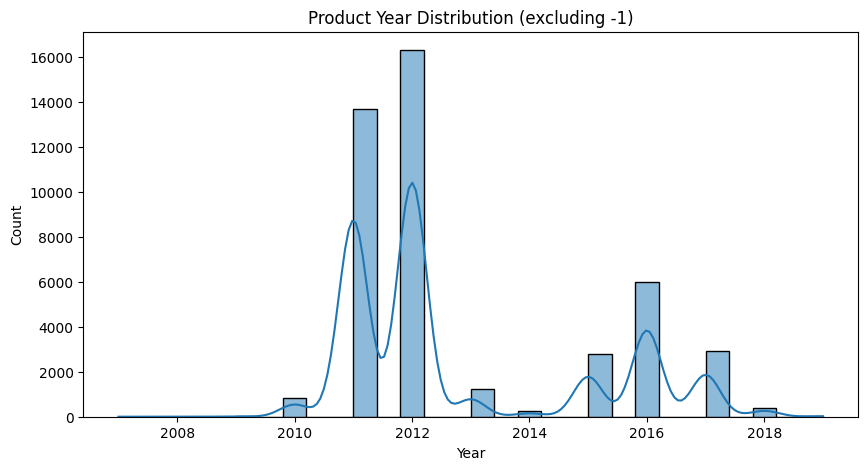

In [38]:
# Year distribution (excluding -1)
years = products[products['year'] != -1]['year']
plt.figure(figsize=(10,5))
sns.histplot(years, bins=30, kde=True)
plt.title('Product Year Distribution (excluding -1)')
plt.xlabel('Year')
plt.show()

In [39]:
# Brands with only 1 product (rare)
rare_brands = products['brand'].value_counts()[products['brand'].value_counts() == 1]
print(f"Number of brands with only 1 product: {len(rare_brands)}")

Number of brands with only 1 product: 0


In [40]:
# Check for missing values
print("Missing values:\n", products.isnull().sum())

# Critical columns should have no missing values
critical = ['masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'usage']
assert products[critical].isnull().sum().sum() == 0, "Missing values in critical columns!"

Missing values:
 id                    0
gender                0
masterCategory        0
subCategory           0
articleType           0
baseColour            0
season                0
year                  0
usage                 0
productDisplayName    0
metadata_status       0
brand                 0
dtype: int64


In [41]:

products.to_parquet('../data/interim/products_clean.parquet', index=False)